# Risk-neutral valuation in SigAlg with binomial trees

In [1]:
# If running in Google Colab, uncomment the line below and run this cell first.
# Also, for Mac+Chrome users, beware of a known bug with LaTeX redering in Colab: https://github.com/googlecolab/colabtools/issues/3192

# !pip install sigalg

## The binomial pricing model

### Setting the scene: stochastic processes

SigAlg models price trajectories of assets as *discrete-time stochastic processes*. Such an object is a collection of random variables $S_t$ (indexed over $t\in \{0,1,\ldots,T\}$) on a fixed probability space $(\Omega, \mathcal{F},P)$. For each sample point $\omega\in \Omega$, we have a sequence of real numbers
$$
(S_0(\omega), S_1(\omega),\ldots,S_T(\omega))\in \mathbb{R}^{T+1},
$$
which is understood as a potential price trajectory of the asset. As the sample point $\omega \in \Omega$ varies, we get different price trajectories, and a price trajectory $(s_0,s_1,\ldots,s_T)\in \mathbb{R}^{T+1}$ has a probability of being observed determined by the probability measure:
$$
P(S_0 = s_0, S_1=s_1,\ldots,S_T=s_T).
$$
The object $\mathcal{F}$ is the *$\sigma$-algebra* of the probability space (the namesake of SigAlg) which, in a sense, encodes the "total information" at hand. It is equipped with a *filtration* induced by the stochastic process, which is a sequence of sub-$\sigma$-algebras terminating with $\mathcal{F}$ itself:
$$
\mathcal{F}_0 \subset \mathcal{F}_1 \subset \cdots \subset \mathcal{F}_T = \mathcal{F}.
$$
The $t$-th $\sigma$-algebra in this filtration is the one generated by the stochastic process up to time $t$:
$$
\mathcal{F}_t = \sigma(S_0,S_1,\ldots,S_t).
$$
The reader unfamiliar with measure-theoretic probability theory should understand $\mathcal{F}_t$ as a partition of the sample space (assuming the sample space is finite, which it always is in SigAlg): Two sample points $\omega$ and $\omega'$ are in the same $\mathcal{F}_t$-component of $\Omega$ if and only if their length-$t$ partial trajectories are equal:
$$
(S_0(\omega),S_1(\omega),\ldots,S_t(\omega)) = (S_0(\omega'),S_1(\omega'),\ldots,S_t(\omega')).
$$
We will also deal with *$\mathcal{F}_t$-measurable random variables*. These are just random variables $X$ on $(\Omega, \mathcal{F}, P)$ that are constant on the $\mathcal{F}_t$-components.

### The definition

A *binomial model* is discrete-time stochastic process $S_t$ that models asset prices with particularly simple dynamics. At any given instant of time $t$, the current price $S_t(\omega)$ may either move up by a factor of $u$, or down by a factor of $d$ (we assume $0< d < 1 < u$), so that either $S_{t+1}(\omega) = uS_t(\omega)$ or $S_{t+1}(\omega) = dS_t(\omega)$. We assume the up-move occurs with probability $p$, the down-move with probability $1-p$, and that the price moves are independent over time. We also assume that the initial price $S_0$ is deterministic. The range of the random variable $S_t$ is the set
$$
\{S_0 u^{n}d^{t-n} : n=0,1,\ldots,n\},
$$
and the distribution of $S_t$ is given by
$$
P \left( S_t = u^{n}d^{t-n}\right) = \binom{t}{n}p^n(1-p)^{t-n},
$$
for each $n=0,1,\ldots,t$. The probability measure $P$ is called the *real-world measure*, to distinguish it from another probability measure that will come later.

In the following code block, we implement a binomial model in SigAlg with the following parameters:

$$
S_0 = 100, \quad u = 1.1, \quad d = 0.9, \quad p = 0.7, \quad R = 1.05, \quad T = 3.
$$

The parameter $R$ is the per-period *risk-free gross return*, which we will discuss below.

In [2]:
import sigalg as sa

S_0, u, d, p, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)
print(S)

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9


Note that the default sample space generated by SigAlg is the set of integers $\Omega=\{0,1,\ldots,7\}$. For each $\omega\in \Omega$, the corresponding row of the printout gives the price trajectory
$$
(S_0(\omega), S_1(\omega), S_2(\omega), S_3(\omega)).
$$
There are exactly $2^T = 2^3 =8$ distinct price trajectories. We may plot them through the `plot_trajectories` method of the model.

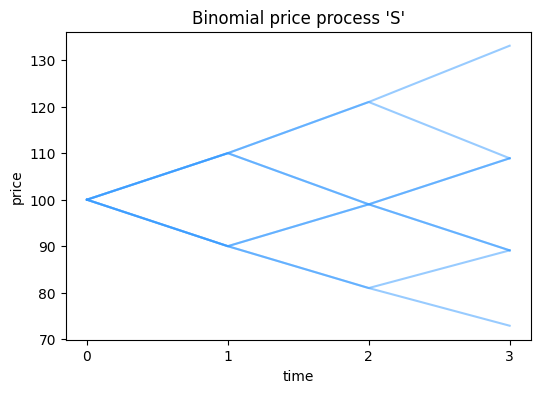

In [3]:
import matplotlib.pyplot as plt

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(ax=ax, colors=[sa.blue], plot_kwargs={"alpha": 0.5})
plt.show()

The real-world probability measure $P$ is accessible via an appropriate attribute of the model.

In [4]:
P = S.prob_measure
print(P)

Probability measure 'P':
           P
omega       
0      0.343
1      0.147
2      0.147
3      0.063
4      0.147
5      0.063
6      0.063
7      0.027


We may push this measure forward through the random variable $S_3$ to get the probability distribution of the four distinct terminal asset prices. This uses the `>>` operator for pushforwards.

In [5]:
print(P >> S[3])

Probability measure 'P_S_3':
       P_S_3
S_3         
72.9   0.027
89.1   0.189
108.9  0.441
133.1  0.343


Note that these probabilities match the binomial distribution with parameter $p$:

In [6]:
(1 - p) ** 3, 3 * p * (1 - p) ** 2, 3 * p**2 * (1 - p), p**3

(0.027000000000000014, 0.18900000000000003, 0.441, 0.3429999999999999)

### Generation modes

For the binomial model above with $T=3$, there are eight distinct price trajectories, but only four terminal prices. Instead of exhaustively enumerating all $2^T$ price trajectories, sometimes it is convenient to generate a smaller representative collection of $T+1$ trajectories. This may be accomplished by setting the parameter `enum_mode="sparse"` in the call to `generate`.

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0   90.0   99.0  108.9
2      100.0   90.0   81.0   89.1
3      100.0   90.0   81.0   72.9


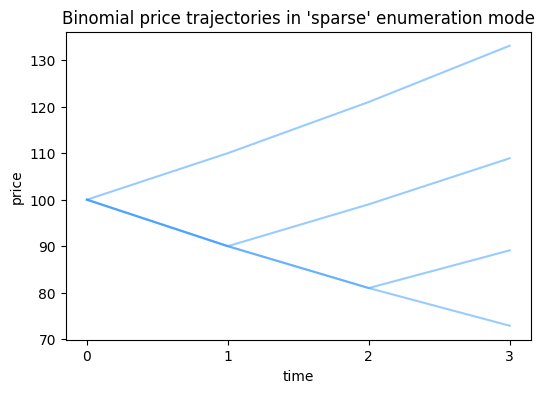

In [7]:
S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p,
    risk_free_gross_return=R,
    enum_mode="sparse",
    mode="enum",
    length=T,
    name="S",
)
print(S)

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(
    ax=ax,
    title="Binomial price trajectories in 'sparse' enumeration mode",
    colors=[sa.blue],
    plot_kwargs={"alpha": 0.5},
)
plt.show()

The representative price trajectories in `sparse` mode are those that do not mix up- and down-moves: All the down-moves are performed first, then all the up-moves.

In addition to sparse enumeration, SigAlg also supports Monte Carlo simulation by setting `mode="sim"`, and specifying the number of trajectories to simulate. We demonstrate this in the next code cell with a new set of parameters and a longer time horizon of $T=100$.

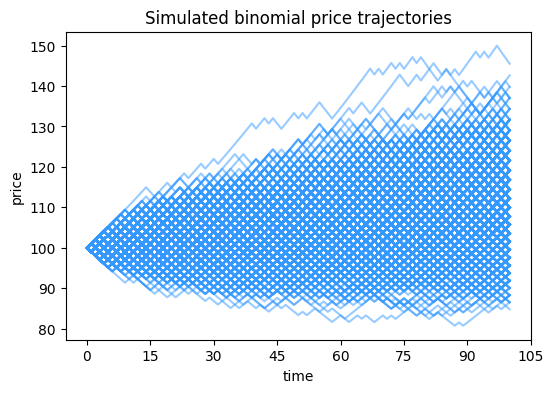

In [8]:
S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=1.01,
    down_factor=0.99,
    up_prob=0.55,
    risk_free_gross_return=1.005,
    mode="sim",
    n_trajectories=1_000,
    length=100,
    name="S",
)

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(
    ax=ax,
    title="Simulated binomial price trajectories",
    colors=[sa.blue],
    plot_kwargs={"alpha": 0.5},
)
plt.show()

## Contingent claims

### The definition

Let $S_t$ be the price process of an asset, indexed $t\in \{0,1,\ldots,T\}$ out to some time horizon $T$. A *contingent claim* (or simply a *claim*) is a stochastic process $\Phi_t$ *adapted* to the filtration $\mathcal{F}_t$ introduced in the previous section. This just means that each $\Phi_t$ is $\mathcal{F}_t$-measurable (for all $t$), which is equivalent to requiring that it is a function of all prices up to (and including) $S_t$:
$$
\Phi_t = \Phi_t(S_0,S_1,\ldots,S_t).
$$
The claim is called *path-independent* if each $\Phi_t$ is $S_t$-measurable (for all $t$), which means that it is a function of the current price alone:
$$
\Phi_t = \Phi_t(S_t).
$$
The time horizon $T$ is called the *maturity time* of the claim. The claim is said to be a *non-early-exercise* claim if $\Phi_t = 0$ for all non-maturity times $t<T$; otherwise, the claim is said to *allow early exercise*.

### Examples

#### European options

One of the simplest examples of a non-early-exercise claim is a *European call option* given by
$$
\Phi_T = \max(S_T-K,0),
$$
where $K$ is a positive real number called the *strike price* of the claim. We may implement this claim in SigAlg by hand using the `from_random_variables` constructor of the `Claim` class. We use a binomial model as the underlying price process $S_t$.

In [9]:
S_0, u, d, p, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)

K = 100
Phi_T = (S[T] - K).max(0)

euro_call = sa.Claim.from_random_variables(
    rvs=[Phi_T], times=[T], model=S, name="euro_call"
)

print("The asset pricing model:")
print(S)

print("\nThe claim payoff at maturity:")
print(Phi_T)

print("\nThe European call option:")
print(euro_call)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The claim payoff at maturity:
Random variable 'max((S_3 - 100), 0)':
       max((S_3 - 100), 0)
omega                     
0                     33.1
1                      8.9
2                      8.9
3                      0.0
4                      8.9
5                      0.0
6                      0.0
7                      0.0

The European call option:
Claim 'euro_call':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0  33.1
1      0.0  0.0  0.0   8.9
2      0.0  0.0  0.0   8.9
3      0.0  0.0  0.0   0.0
4      0.0  0.0  0.0   8.9
5      0.0  0.0  0.0   0.0
6    

A *European put option* is a non-early-exercise claim with
$$
\Phi_T = \max(K-S_T,0).
$$
It may be implemented in SigAlg by hand just as easily as the call option above; however, SigAlg also includes convenient factory methods for typical contingent claims. The next code block uses one of these methods to construct a European put option in one line.

In [10]:
euro_put = sa.Claim.european_option(strike=K, model=S, type="put", name="euro_put")

print("The asset pricing model:")
print(S)

print("\nThe European put option:")
print(euro_put)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The European put option:
European option 'euro_put':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0   0.0
1      0.0  0.0  0.0   0.0
2      0.0  0.0  0.0   0.0
3      0.0  0.0  0.0  10.9
4      0.0  0.0  0.0   0.0
5      0.0  0.0  0.0  10.9
6      0.0  0.0  0.0  10.9
7      0.0  0.0  0.0  27.1


#### American options

American options are just European options (as defined above) that allow early exercise. In particular, an *American call option* with strike $K$ is a claim with

$$
\Phi_t = \max(S_t-K,0)
$$

for all $t$, while an *American put option* with strike $K$ is given by

$$
\Phi_t = \max(K-S_t, 0)
$$

for all $t$. In the first of the next two code blocks, we build an American call option by hand to again illustrate the naturality of the SigAlg API, and then in the second we use a factory method to build an American put option in one line.

In [11]:
Phi = (S - K).max(0)

american_call = sa.Claim.from_stochastic_process(
    process=Phi, model=S, name="american_call"
)

print("The asset pricing model:")
print(S)

print("\nThe American call option:")
print(american_call)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The American call option:
Claim 'american_call':
t        0     1     2     3
omega                       
0      0.0  10.0  21.0  33.1
1      0.0  10.0  21.0   8.9
2      0.0  10.0   0.0   8.9
3      0.0  10.0   0.0   0.0
4      0.0   0.0   0.0   8.9
5      0.0   0.0   0.0   0.0
6      0.0   0.0   0.0   0.0
7      0.0   0.0   0.0   0.0


In [12]:
american_put = sa.Claim.american_option(
    strike=K, model=S, type="put", name="american_put"
)

print("The asset pricing model:")
print(S)

print("\nThe American put option:")
print(american_put)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The American put option:
American option 'american_put':
t        0     1     2     3
omega                       
0      0.0   0.0   0.0   0.0
1      0.0   0.0   0.0   0.0
2      0.0   0.0   1.0   0.0
3      0.0   0.0   1.0  10.9
4      0.0  10.0   1.0   0.0
5      0.0  10.0   1.0  10.9
6      0.0  10.0  19.0  10.9
7      0.0  10.0  19.0  27.1


#### Asian options

European and American options are path-independent claims. An example of a path-dependent claim is an *Asian call option* with strike $K$ is given by
$$
\Phi_t = \max(\overline{S}_t- K,0)
$$
for all $t$, where
$$
\overline{S}_t = \frac{1}{1+t} \sum_{k=0}^t S_k
$$
for each $t$. Similarly, an *Asian put option* with strike $K$ is given by
$$
\Phi_t = \max(K-\overline{S}_t,0).
$$
The next pair of code cells follows the pattern above: First constructing an Asian call option by hand, then using a factory method to construct an Asian put option.

In [13]:
Phi = (S.cumavg() - K).max(0)

asian_call = sa.Claim.from_stochastic_process(
    process=Phi, model=S, name="asian_call"
)

print("The asset pricing model:")
print(S)

print("\nThe Asian call option:")
print(asian_call)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The Asian call option:
Claim 'asian_call':
t        0    1          2       3
omega                             
0      0.0  5.0  10.333333  16.025
1      0.0  5.0  10.333333   9.975
2      0.0  5.0   3.000000   4.475
3      0.0  5.0   3.000000   0.000
4      0.0  0.0   0.000000   0.000
5      0.0  0.0   0.000000   0.000
6      0.0  0.0   0.000000   0.000
7      0.0  0.0   0.000000   0.000


In [14]:
asian_put = sa.Claim.asian_option(strike=K, model=S, type="put", name="asian_put")

print("The asset pricing model:")
print(S)

print("\nThe Asian put option:")
print(asian_put)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The Asian put option:
Asian option 'asian_put':
t        0    1    2       3
omega                       
0      0.0  0.0  0.0   0.000
1      0.0  0.0  0.0   0.000
2      0.0  0.0  0.0   0.000
3      0.0  0.0  0.0   0.475
4      0.0  0.0  0.0   0.525
5      0.0  0.0  0.0   5.475
6      0.0  0.0  0.0   9.975
7      0.0  0.0  0.0  14.025


#### Other exotic claims

The SigAlg API allows the user to construct claims with all different types of payoff structures. How about a claim that is a mix of an Asian call and a European put, and only allows exercise at two specified times?

In [15]:
Phi_1 = (K - S[1]).max(0)
Phi_3 = (S.cumavg()[3] - K).max(0)

exotic_claim = sa.Claim.from_random_variables(
    rvs=[Phi_1, Phi_3], times=[1, 3], model=S, name="exotic_claim"
)

print("The asset pricing model:")
print(S)

print("\nThe exotic claim:")
print(exotic_claim)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The exotic claim:
Claim 'exotic_claim':
t        0     1    2       3
omega                        
0      0.0   0.0  0.0  16.025
1      0.0   0.0  0.0   9.975
2      0.0   0.0  0.0   4.475
3      0.0   0.0  0.0   0.000
4      0.0  10.0  0.0   0.000
5      0.0  10.0  0.0   0.000
6      0.0  10.0  0.0   0.000
7      0.0  10.0  0.0   0.000


## Pricing contingent claims

Not every choice of $u$, $d$, and $R$ gives an economically sensible market. If $R \geq u$, the riskless bond always outperforms the stock, so there is no reason to ever hold stock; if $R \leq d$, the reverse is true. Either way, there would be an *arbitrage* — a trading strategy with no initial cost, no risk of loss, and a positive probability of profit. The model is arbitrage-free exactly when

$$
d < R < u.
$$

The **First Fundamental Theorem of Asset Pricing** says that this no-arbitrage condition is equivalent to the existence of an *equivalent martingale measure* (EMM) $Q$ — a probability measure, equivalent to the real-world measure $P$, under which the discounted price process is a martingale. For the binomial model, $Q$ is unique, and is determined by the risk-neutral probabilities

$$
q_u = \frac{R-d}{u-d}, \qquad q_d = 1 - q_u.
$$

Note that $q_u$ and $q_d$ depend only on $u$, $d$, and $R$ — *not* on the real-world probability $p$!

In [16]:
q_u, q_d = S.risk_neutral_probs()
print(q_u, q_d)

0.7499999999999999 0.2500000000000001


In [17]:
Q = S.emm()
print(Q)

Probability measure 'Q':
              Q
omega          
0      0.421875
1      0.140625
2      0.140625
3      0.046875
4      0.140625
5      0.046875
6      0.046875
7      0.015625


We can verify the martingale property directly: the discounted price process $S_t/R^t$ should be a martingale with respect to $Q$.

In [18]:
S.discount(rate=r).is_martingale(prob_measure=Q)

NameError: name 'r' is not defined

> **Exercise.** Try generating a model with `risk_free_rate` set so large that $R \geq u$ (for instance, `risk_free_rate=0.2` with `up_factor=1.1`), and call `risk_neutral_probs()` on it. You should see a `ValueError` complaining about arbitrage — confirming the theorem above.

In [ ]:
S_arbitrage = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p,
    risk_free_rate=0.2,
    mode="enum",
    length=1,
    name="S",
)
try:
    S_arbitrage.risk_neutral_probs()
except ValueError as e:
    print(f"{type(e).__name__}: {e}")

ValueError: There is arbitrage in the model. The risk-free gross return R must be in the interval [down_factor, up_factor].


## Pricing a European claim

A **contingent claim** is a stochastic process $\Phi$ whose value $\Phi_t(\omega)$ represents a payoff that may be collected at time $t$ in state $\omega$. The simplest claims — *European* claims — pay off only at the final time $T$. SigAlg's `Claim` class represents such objects, with convenient factory methods for standard payoffs.

Let's build a European call option with strike $K=100$.

In [ ]:
K = 100
euro_call = sa.Claim.european_option(model=S, strike=K, type="call", name="euro_call")
print(euro_call)

European option 'euro_call':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0  33.1
1      0.0  0.0  0.0   8.9
2      0.0  0.0  0.0   8.9
3      0.0  0.0  0.0   0.0
4      0.0  0.0  0.0   8.9
5      0.0  0.0  0.0   0.0
6      0.0  0.0  0.0   0.0
7      0.0  0.0  0.0   0.0


Because the market is complete and arbitrage-free, there is a unique no-arbitrage price for this claim: its discounted expected payoff under the risk-neutral measure $Q$,

$$
X_0 = \frac{1}{R^T}\,E_Q\!\left(\Phi_T\right).
$$

Notice that this formula uses the risk-neutral measure $Q$, *not* the real-world measure $P$ — and this is exactly what the `price` method computes.

In [ ]:
S.price(claim=euro_call)

15.306122448979611

## American claims and optimal stopping

An **American claim** may be exercised at *any* time up to and including maturity, not just at the end. The holder must solve an optimal stopping problem: at each time $t$, compare the *intrinsic value* $\Phi_t$ (the payoff from exercising now) against the *continuation value* — the discounted risk-neutral expectation of continuing — and exercise whenever the intrinsic value is at least as large. This leads to the backward-induction recursion

$$
V_T = \Phi_T, \qquad V_t = \max\!\left(\Phi_t,\ \tfrac{1}{R}\,E_Q\!\left(V_{t+1}\mid \mathcal{F}_t\right)\right), \quad 0\le t<T.
$$

Let's price an American put with the same strike.

In [ ]:
american_put = sa.Claim.american_option(model=S, strike=K, type="put", name="american_put")
print(american_put)

American option 'american_put':
t        0     1     2     3
omega                       
0      0.0   0.0   0.0   0.0
1      0.0   0.0   0.0   0.0
2      0.0   0.0   1.0   0.0
3      0.0   0.0   1.0  10.9
4      0.0  10.0   1.0   0.0
5      0.0  10.0   1.0  10.9
6      0.0  10.0  19.0  10.9
7      0.0  10.0  19.0  27.1


In [ ]:
S.price(claim=american_put)

2.822319403952058

Since this claim allows early exercise, SigAlg runs the full backward-induction recursion above, rather than the closed-form expectation formula used for the European call. We can inspect every quantity that recursion produces: the price process $V_t$ itself, the continuation value, and the optimal exercise time $\tau$.

In [ ]:
print(S.price_process(claim=american_put))

Stochastic process 'X':
t             0          1          2     3
omega                                      
0      2.822319   0.617914   0.000000   0.0
1      2.822319   0.617914   0.000000   0.0
2      2.822319   0.617914   2.595238   0.0
3      2.822319   0.617914   2.595238  10.9
4      2.822319  10.000000   2.595238   0.0
5      2.822319  10.000000   2.595238  10.9
6      2.822319  10.000000  19.000000  10.9
7      2.822319  10.000000  19.000000  27.1


In [ ]:
print(S.continuation_process(claim=american_put))

Stochastic process 'V':
t             0         1          2     3
omega                                     
0      2.822319  0.617914   0.000000   0.0
1      2.822319  0.617914   0.000000   0.0
2      2.822319  0.617914   2.595238   0.0
3      2.822319  0.617914   2.595238  10.9
4      2.822319  6.377551   2.595238   0.0
5      2.822319  6.377551   2.595238  10.9
6      2.822319  6.377551  14.238095  10.9
7      2.822319  6.377551  14.238095  27.1


In [ ]:
tau = S.exercise_time(claim=american_put)
print(tau)

Stopping time 'tau':
       tau
omega     
0      inf
1      inf
2      inf
3      3.0
4      1.0
5      1.0
6      1.0
7      1.0


The value `inf` means the holder should *never* exercise early along that path — they should hold the option all the way to maturity $T=3$. Let's visualize the exercise decision directly on the price tree: each purple dot marks the $(t, S_t(\omega))$ node at which the American put is optimally exercised.

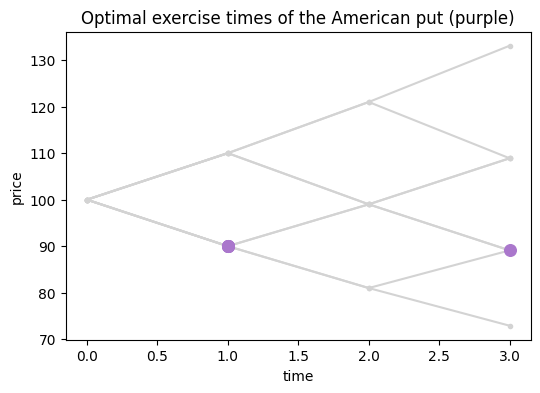

In [ ]:
import numpy as np

fig, ax = plt.subplots(figsize=(6, 4))
for _, row in S.data.iterrows():
    ax.plot(S.time.data, row, color="lightgray", marker="o", markersize=3, zorder=1)

for omega, t_star in tau.data.items():
    if np.isfinite(t_star):
        t_star = int(t_star)
        ax.scatter(t_star, S.data.loc[omega, t_star], color=purple, zorder=5, s=70)

ax.set_xlabel("time")
ax.set_ylabel("price")
ax.set_title("Optimal exercise times of the American put (purple)")
plt.show()

As expected for a put, exercise only ever happens when the price has fallen — never when it has risen above the strike.

> **Exercise.** Build an American *call* option on the same model (`type="call"`) and compute its price and exercise time. Since this underlying stock pays no dividends, you should find that the American call is *never* worth exercising early, so its price should match the European call exactly. Can you explain why, economically?

## Hedging and replication

The **Second Fundamental Theorem of Asset Pricing** says that, in a complete market, every claim can be *replicated*: there is a self-financing trading strategy in the stock and bond whose value process exactly matches the claim's price process, at every time and in every state. For the binomial model, this replicating strategy can be computed explicitly via `replicating_portfolio`, which returns three processes:

* `Delta` — the number of shares of stock held at each time,
* `B` — the dollar value of the bond position held at each time,
* `V` — the total value of the portfolio, which coincides with the claim's price process.

Let's compute the replicating portfolio for the European call.

In [ ]:
Delta, B, V = S.replicating_portfolio(claim=euro_call)

print(Delta)

Stochastic process 'Delta':
t             0         1         2
omega                              
0      0.768707  0.882035  1.000000
1      0.768707  0.882035  1.000000
2      0.768707  0.882035  0.449495
3      0.768707  0.882035  0.449495
4      0.768707  0.353175  0.449495
5      0.768707  0.353175  0.449495
6      0.768707  0.353175 -0.000000
7      0.768707  0.353175 -0.000000


In [ ]:
print(B)

Stochastic process 'B':
t              0          1          2
omega                                 
0     -61.564626 -77.108844 -95.238095
1     -61.564626 -77.108844 -95.238095
2     -61.564626 -77.108844 -38.142857
3     -61.564626 -77.108844 -38.142857
4     -61.564626 -27.244898 -38.142857
5     -61.564626 -27.244898 -38.142857
6     -61.564626 -27.244898   0.000000
7     -61.564626 -27.244898   0.000000


In [ ]:
print(V)

Stochastic process 'V':
t              0          1          2     3
omega                                       
0      15.306122  19.914966  25.761905  33.1
1      15.306122  19.914966  25.761905   8.9
2      15.306122  19.914966   6.357143   8.9
3      15.306122  19.914966   6.357143   0.0
4      15.306122   4.540816   6.357143   8.9
5      15.306122   4.540816   6.357143   0.0
6      15.306122   4.540816   0.000000   0.0
7      15.306122   4.540816   0.000000   0.0


By construction, the portfolio's value at each time $t$ is $\Delta_t S_t + B_t$, which should exactly equal $V_t$.

In [ ]:
trade_times = Delta.time.data
check = Delta.data[trade_times].values * S.data[trade_times].values + B.data[trade_times].values
np.allclose(check, V.data[trade_times].values)

True

More importantly, the strategy is **self-financing**: if we hold $(\Delta_t, B_t)$ from time $t$ to $t+1$ — letting the stock move to its new price $S_{t+1}$ and the bond grow by a factor $R$ — the resulting value matches $V_{t+1}$ exactly, in *every* state, with no extra cash injected or withdrawn along the way.

In [ ]:
R = 1 + r
for t in [0, 1, 2]:
    grown_value = Delta.data[t] * S.data[t + 1] + B.data[t] * R
    matches = np.allclose(grown_value.values, V.data[t + 1].values)
    print(f"t={t} -> t+1={t+1}: self-financing holds = {matches}")

t=0 -> t+1=1: self-financing holds = True
t=1 -> t+1=2: self-financing holds = True
t=2 -> t+1=3: self-financing holds = True


This is the essence of replication: an investor who sells the call for $X_0 = 15.31$ and follows this trading strategy can perfectly hedge their obligation to pay $\Phi_T$ at maturity, regardless of which way the market moves.

> **Exercise.** Compute the replicating portfolio for the American put defined above. (Hint: `replicating_portfolio` works for early-exercise claims too — but now you should check the self-financing identity only *up to* the exercise time $\tau$, since the position is unwound once the holder exercises.)

## Summary

In this tutorial we used SigAlg's `BinomialPricingModel` to:

1. Generate price trajectories by dense enumeration, sparse enumeration, and simulation.
2. Compute the unique risk-neutral measure $Q$ and verify the First Fundamental Theorem of Asset Pricing.
3. Price a European claim via risk-neutral expectation, and an American claim via backward induction and optimal stopping.
4. Compute an explicit replicating portfolio and verify the Second Fundamental Theorem of Asset Pricing numerically.

All of this relied crucially on *completeness*: the binomial model has exactly as many traded assets (two) as there are possible moves at each step (two), which is what makes the EMM unique and replication possible. In the next tutorial, we move to the **trinomial model**, where there are three possible moves at each step but still only two traded assets — and we will see exactly what goes wrong when a market is *incomplete*.